# MuJoCo settings from physical scales

ARIEL does not hand-tune MuJoCo. Ten physical-scale **seeds** (a length scale, a top speed, gravity, air density and so on, written as astropy quantities) generate every setting of the engine: the timestep, the contact softness, the fluid forces and the rest.

In this notebook you see the derivation table, change a seed and watch the timestep follow, list what differs from MuJoCo's own defaults, check the values against plausible bands, and compile the generated model. No graphics are needed.

In [1]:
# Standard library
import math

In [2]:
# Third-party libraries
import astropy.units as u
import matplotlib.pyplot as plt
import mujoco
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.simulators import compile_model
from ariel.simulators.mujoco import Seeds, generate_xml
from ariel.simulators.mujoco.bands import evaluate_bands
from ariel.simulators.mujoco.mjcf import differences
from ariel.simulators.mujoco.settings import engine_defaults
from ariel.simulators.mujoco.table import derivation_table

Nothing here is random: the seeds have fixed defaults, so every run prints the same numbers.

In [4]:
# Expected with the default seeds
DIFFERENT_SETTINGS = 21  # of 156

## The seeds and what they give

`Seeds()` holds the defaults. `derivation_table` lists every seed, then every value derived from it, with the unit and where the rule comes from.

In [5]:
seeds = Seeds()
table = Table(title="Seeds and derived values")
for column in ("name", "value", "unit", "kind"):
    table.add_column(column)
for row in derivation_table(seeds):
    table.add_row(row.name, f"{row.value:g}", row.unit, row.kind)
console.print(table)

                Seeds and derived values                
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┓
┃ name                  ┃ value    ┃ unit    ┃ kind    ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━┩
│ length_scale          │ 0.075    │ m       │ seed    │
│ top_speed             │ 1        │ m / s   │ seed    │
│ joint_frequency       │ 100      │ rad / s │ seed    │
│ gravity               │ 9.80665  │ m / s2  │ seed    │
│ air_density           │ 1.204    │ kg / m3 │ seed    │
│ air_viscosity         │ 1.81e-05 │ Pa s    │ seed    │
│ friction              │ 1        │         │ seed    │
│ alpha                 │ 0.05     │         │ seed    │
│ kappa                 │ 0.28     │         │ seed    │
│ gamma                 │ 0.5      │         │ seed    │
│ contact_time_constant │ 0.021    │ s       │ formula │
│ advection_limit       │ 0.00375  │ s       │ formula │
│ joint_limit           │ 0.005    │ s       │ formula │
│ timestep              │ 0.00375  │ s       │ formula │
│ timestep_over_contact │ 0.178571 │         │ formula │
│ courant               │ 0.05     │         │ formula │
└───────────────────────┴──────────┴─────────┴─────────┘

In [6]:
# The timestep is the smallest of three limits, here 3.75 ms
# (the length scale is the measured brick's 7.5 cm edge).
step_ms = seeds.timestep * 1000
console.print(f"timestep {step_ms:.2f} ms, set by {seeds.timestep_limit}")
assert math.isclose(seeds.timestep, 0.00375)
assert math.isclose(seeds.contact_time_constant, 0.021)

timestep 3.75 ms, set by advection

## Change a seed

`replace` returns a new, validated `Seeds`. A robot twice as big (length scale 0.15 m instead of the brick's 0.075 m) can afford a larger step. The chart shows the three limits for both; the timestep is the lowest bar of each group.

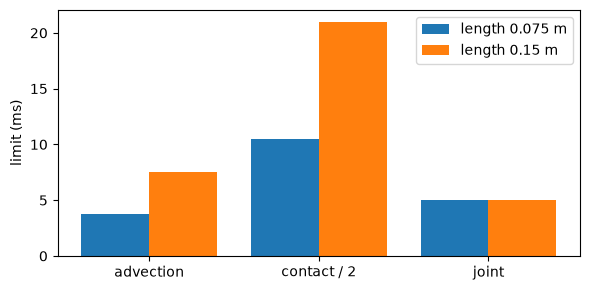

In [7]:
big = seeds.replace(length_scale=0.15 * u.m)
limits = {
    "advection": (seeds.advection_limit, big.advection_limit),
    "contact / 2": (
        seeds.contact_time_constant / 2,
        big.contact_time_constant / 2,
    ),
    "joint": (seeds.joint_limit, big.joint_limit),
}
fig, ax = plt.subplots(figsize=(6, 3))
positions = range(len(limits))
ax.bar(
    [p - 0.2 for p in positions],
    [v[0] * 1000 for v in limits.values()],
    0.4,
    label="length 0.075 m",
)
ax.bar(
    [p + 0.2 for p in positions],
    [v[1] * 1000 for v in limits.values()],
    0.4,
    label="length 0.15 m",
)
ax.set_xticks(list(positions), list(limits))
ax.set_ylabel("limit (ms)")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
console.print(
    f"timestep: {seeds.timestep * 1000:.2f} ms -> {big.timestep * 1000:.2f} ms"
)
assert big.timestep > seeds.timestep
assert math.isclose(seeds.length_scale.value, 0.075)  # unchanged

timestep: 3.75 ms -> 5.00 ms

## What differs from MuJoCo's defaults

`differences` lists only the settings whose generated value is not MuJoCo's default, each with its reason. The rest of the 150 or so settings stay at the engine's values.

In [9]:
defaults = engine_defaults()
changed = differences(seeds)
table = Table(title=f"{len(changed)} of {len(defaults)} settings differ")
for column in ("setting", "MuJoCo default", "ARIEL", "reason"):
    table.add_column(column, overflow="fold")
for setting in changed:
    table.add_row(
        setting.name,
        str(defaults[setting.name]),
        str(setting.value),
        setting.reason,
    )
console.print(table)

                                             21 of 156 settings differ                                             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ setting                    ┃ MuJoCo default             ┃ ARIEL                   ┃ reason                      ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ option.density             │ 0.0                        │ 1.204                   │ air density seed (medium    │
│                            │                            │                         │ for fluid forces)           │
│ option.gravity             │ (0.0, 0.0, -9.81)          │ (0.0, 0.0, -9.80665)    │ gravity seed, pointing down │
│                            │                            │                         │ the z axis                  │
│ option.integrator          │ 0                          │ 3                       │ implicitfast is the         │
│                            │                            │                         │ documented general          │
│                            │                            │                         │ recommendation and what     │
│                            │                            │                         │ ARIEL already used (old     │
│                            │                            │                         │ MujocoConfig)               │
│ option.timestep            │ 0.002                      │ 0.00375                 │ derived from the seeds, see │
│                            │                            │                         │ timestep in the table       │
│ option.viscosity           │ 0.0                        │ 1.81e-05                │ air viscosity seed (medium  │
│                            │                            │                         │ for fluid forces)           │
│ compiler.balanceinertia    │ False                      │ True                    │ accept slightly             │
│                            │                            │                         │ inconsistent inertias of    │
│                            │                            │                         │ generated bodies; what      │
│                            │                            │                         │ ARIEL already used (old     │
│                            │                            │                         │ MujocoConfig)               │
│ compiler.degree            │ True                       │ False                   │ ARIEL code uses radians;    │
│                            │                            │                         │ what ARIEL already used     │
│                            │                            │                         │ (old MujocoConfig)          │
│ visual.global_.azimuth     │ 90.0                       │ 140.0                   │ ARIEL's own look of the     │
│                            │                            │                         │ viewer; what ARIEL already  │
│                            │                            │                         │ used (old                   │
│                            │                            │                         │ BaseWorld._init_spec)       │
│ visual.global_.elevation   │ -45.0                      │ -20.0                   │ ARIEL's own look of the     │
│                            │                            │                         │ viewer; what ARIEL already  │
│                            │                            │                         │ used (old                   │
│                            │                            │                         │ BaseWorld._init_spec)       │
│ visual.global_.offheight   │ 480                        │ 960                     │ offscreen render height;    │
│                            │                          

In [10]:
names = {setting.name for setting in changed}
assert {"option.timestep", "option.gravity", "default.geom.solref"} <= names
assert len(changed) == DIFFERENT_SETTINGS

## Plausible bands

A band is the range a quantity should stay in for the simulation to behave. `evaluate_bands` checks every derived value against its band.

In [11]:
results = evaluate_bands(seeds)
table = Table(title="Bands")
for column in ("quantity", "value", "low", "high", "inside"):
    table.add_column(column)
for result in results:
    table.add_row(
        result.name,
        f"{result.value:g}",
        f"{result.low:g}",
        f"{result.high:g}",
        "yes" if result.inside else "NO",
    )
console.print(table)
assert all(result.inside for result in results)

                              Bands                              
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┓
┃ quantity              ┃ value    ┃ low     ┃ high    ┃ inside ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━┩
│ timestep              │ 0.00375  │ 0.0005  │ 0.005   │ yes    │
│ timestep_over_contact │ 0.178571 │ 0.01    │ 0.5     │ yes    │
│ courant               │ 0.05     │ 0       │ 0.05    │ yes    │
│ gravity               │ 9.80665  │ 9       │ 10      │ yes    │
│ air_density           │ 1.204    │ 0.8     │ 1.4     │ yes    │
│ air_viscosity         │ 1.81e-05 │ 1.5e-05 │ 2.2e-05 │ yes    │
│ friction              │ 1        │ 0.2     │ 1.5     │ yes    │
│ solref_damping_ratio  │ 1        │ 0.7     │ 1.5     │ yes    │
│ solimp_d0             │ 0.9      │ 0.8     │ 0.98    │ yes    │
└───────────────────────┴──────────┴─────────┴─────────┴────────┘

## The generated model

`generate_xml` writes the settings as MJCF. MuJoCo compiles it, and the compiled model carries the derived timestep and gravity.

In [12]:
xml = generate_xml(seeds)
model = compile_model(mujoco.MjSpec.from_string(xml))
console.print(
    f"compiled: timestep {model.opt.timestep}, gravity {model.opt.gravity}"
)
assert math.isclose(model.opt.timestep, seeds.timestep)
assert math.isclose(-model.opt.gravity[2], 9.80665)

compiled: timestep 0.00375, gravity [ 0.       0.      -9.80665]